# Assignment 9 — Image Classification Using Vision Transformer and CNN

## 1. Objective

To perform image classification using a pre-trained Vision Transformer (ViT) model and compare its performance with a Convolutional Neural Network (CNN) model.

## 2. Problem Statement

Implement image classification using the Intel Natural Scenes dataset. Use transfer learning with a pre-trained Vision Transformer (ViT-B/16) and a pre-trained CNN (ResNet18) to classify images into six scene categories. Evaluate and compare both models using appropriate classification metrics.

## 3. Dataset

- **Dataset:** Intel Natural Scenes Classification
- **Source:** [Kaggle — Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
- **Classes:** Buildings, Forest, Glacier, Mountain, Sea, and Street
- **Training and testing:** Use the provided training and test splits. Create a validation split from the training data for model selection.
- **Prediction images:** The unlabeled prediction split is optional and will not be used for supervised evaluation.

## 4. Models

1. **Vision Transformer:** Pre-trained ViT-B/16 with a classification head adapted to six classes.
2. **CNN:** Pre-trained ResNet18 with a classification head adapted to six classes.

## 5. Evaluation Metrics

Evaluate both models using accuracy, precision, recall, F1-score, and a confusion matrix. Compare their classification performance across the six scene categories.

## 6. Expected Outcome

Understand the differences between transformer-based image classification and CNN-based image classification through a controlled transfer-learning experiment.

## Dataset Download, Extraction, and Validation

Download the Intel Natural Scenes dataset using the Kaggle CLI. Verify the downloaded ZIP archive, extract the files into the assignment's data directory, and validate the training and testing splits.

The dataset is stored locally under `data/raw/`. The downloaded archive and extracted images are data artifacts, not source-code files, and should not be committed to Git.

In [1]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import subprocess
import sys

# Configuration
DATA_DIR = Path("data/raw")
ARCHIVE_PATH = DATA_DIR / "intel-image-classification.zip"
DATASET_SLUG = "puneet6060/intel-image-classification"

EXPECTED_CLASSES = {
    "buildings", "forest", "glacier",
    "mountain", "sea", "street",
}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
EXPECTED_SPLITS = ("seg_train/seg_train", "seg_test/seg_test")

DATA_DIR.mkdir(parents=True, exist_ok=True)


def validate_dataset():
    """Return True if both labeled splits contain all six nonempty classes."""
    for split in EXPECTED_SPLITS:
        split_dir = DATA_DIR / split

        if not split_dir.is_dir():
            return False

        class_dirs = {
            path.name: path
            for path in split_dir.iterdir()
            if path.is_dir()
        }

        if not EXPECTED_CLASSES.issubset(class_dirs):
            return False

        for class_name in EXPECTED_CLASSES:
            class_dir = class_dirs[class_name]
            if not any(
                path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
                for path in class_dir.iterdir()
            ):
                return False

    return True


def print_dataset_summary():
    """Print image counts for the labeled dataset splits."""
    for split in EXPECTED_SPLITS:
        split_dir = DATA_DIR / split
        print(f"\n{split}")

        total = 0
        for class_name in sorted(EXPECTED_CLASSES):
            class_dir = split_dir / class_name
            count = sum(
                1 for path in class_dir.iterdir()
                if path.is_file()
                and path.suffix.lower() in IMAGE_EXTENSIONS
            )
            total += count
            print(f"  {class_name:12s} {count:6,d}")

        print(f"  {'TOTAL':12s} {total:6,d}")


# 1. Reuse the dataset if it is already complete.
if validate_dataset():
    print("Dataset already exists and passed validation.")
    print("Skipping download and extraction.")

else:
    print("Dataset is missing or incomplete.")

    # 2. Download a fresh archive.
    print("\n[1/3] Downloading dataset from Kaggle...", flush=True)

    result = subprocess.run(
        [
            sys.executable, "-m", "kaggle", "datasets", "download",
            "-d", DATASET_SLUG,
            "-p", str(DATA_DIR.resolve()),
            "--force",
        ],
        check=False,
    )

    if result.returncode != 0 or not ARCHIVE_PATH.is_file():
        raise RuntimeError(
            "Download failed. Check Kaggle authentication and connectivity."
        )

    # 3. Verify archive integrity.
    print("\n[2/3] Verifying ZIP integrity...", flush=True)

    try:
        with ZipFile(ARCHIVE_PATH) as archive:
            bad_file = archive.testzip()
            if bad_file is not None:
                raise RuntimeError(f"Corrupt ZIP member: {bad_file}")
    except BadZipFile as exc:
        raise RuntimeError("The downloaded ZIP archive is invalid.") from exc

    # 4. Extract only when the dataset needs repair.
    print("\n[3/3] Extracting dataset...", flush=True)

    with ZipFile(ARCHIVE_PATH) as archive:
        archive.extractall(DATA_DIR)

    if not validate_dataset():
        raise RuntimeError(
            "Extraction finished, but dataset validation failed."
        )

    print("Extraction and validation completed successfully.")

# Final summary
print_dataset_summary()
print("\nSUCCESS: Dataset is ready for the assignment.")

Dataset already exists and passed validation.
Skipping download and extraction.

seg_train/seg_train
  buildings     2,191
  forest        2,271
  glacier       2,404
  mountain      2,512
  sea           2,274
  street        2,382
  TOTAL        14,034

seg_test/seg_test
  buildings       437
  forest          474
  glacier         553
  mountain        525
  sea             510
  street          501
  TOTAL         3,000

SUCCESS: Dataset is ready for the assignment.


## Data Exploration and Train–Validation Split

Inspect the class distribution and create a reproducible stratified validation split from the training dataset. The provided test dataset will remain untouched until final evaluation to prevent data leakage.

In [2]:
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

DATA_DIR = Path("data/raw")
TRAIN_DIR = DATA_DIR / "seg_train" / "seg_train"
TEST_DIR = DATA_DIR / "seg_test" / "seg_test"

RANDOM_STATE = 42
VALIDATION_SIZE = 0.2
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# Collect image paths and labels.
image_paths = []
labels = []

class_names = sorted(
    path.name for path in TRAIN_DIR.iterdir() if path.is_dir()
)
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

for class_name in class_names:
    class_dir = TRAIN_DIR / class_name

    for image_path in sorted(class_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            image_paths.append(str(image_path))
            labels.append(class_to_idx[class_name])

# Create a stratified train-validation split.
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=labels,
)

# Collect the test dataset separately.
test_paths = []
test_labels = []

for class_name in class_names:
    class_dir = TEST_DIR / class_name

    for image_path in sorted(class_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            test_paths.append(str(image_path))
            test_labels.append(class_to_idx[class_name])

print("Classes:", class_names)
print("Class-to-index mapping:", class_to_idx)
print(f"\nTraining samples:   {len(train_paths):,}")
print(f"Validation samples: {len(val_paths):,}")
print(f"Test samples:       {len(test_paths):,}")

print("\nTraining distribution:")
for idx, count in sorted(Counter(train_labels).items()):
    print(f"  {class_names[idx]:12s}: {count:,}")

print("\nValidation distribution:")
for idx, count in sorted(Counter(val_labels).items()):
    print(f"  {class_names[idx]:12s}: {count:,}")

assert len(set(train_paths) & set(val_paths)) == 0
assert len(set(train_paths) & set(test_paths)) == 0
assert len(set(val_paths) & set(test_paths)) == 0

print("\nSUCCESS: Stratified split created with no path overlap.")

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class-to-index mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}

Training samples:   11,227
Validation samples: 2,807
Test samples:       3,000

Training distribution:
  buildings   : 1,753
  forest      : 1,817
  glacier     : 1,923
  mountain    : 2,009
  sea         : 1,819
  street      : 1,906

Validation distribution:
  buildings   : 438
  forest      : 454
  glacier     : 481
  mountain    : 503
  sea         : 455
  street      : 476

SUCCESS: Stratified split created with no path overlap.


## Image Preprocessing and Data Loaders

Prepare the Intel Natural Scenes images for transfer learning using pretrained Vision Transformer (ViT-B/16) and ResNet18 models. Apply the appropriate image resizing, tensor conversion, and ImageNet normalization. Create reproducible PyTorch datasets and data loaders for training, validation, and testing.

In [3]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Reproducibility
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Experiment configuration
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
NUM_CLASSES = len(class_names)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet normalization used by both pretrained models.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class SceneDataset(Dataset):
    """Load scene images and their integer class labels."""

    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

        if len(self.paths) != len(self.labels):
            raise ValueError("Image paths and labels must have equal lengths.")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        label = self.labels[index]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


train_dataset = SceneDataset(
    train_paths, train_labels, transform=train_transform
)
val_dataset = SceneDataset(
    val_paths, val_labels, transform=eval_transform
)
test_dataset = SceneDataset(
    test_paths, test_labels, transform=eval_transform
)

# Windows compatibility: this notebook is intended to run in WSL/Linux.
loader_generator = torch.Generator().manual_seed(RANDOM_STATE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset sizes:")
print(f"Training:   {len(train_dataset):,}")
print(f"Validation: {len(val_dataset):,}")
print(f"Testing:    {len(test_dataset):,}")

# Verify a batch before model training.
images, labels_batch = next(iter(train_loader))

print("\nBatch verification:")
print("Image tensor shape:", tuple(images.shape))
print("Label tensor shape:", tuple(labels_batch.shape))
print("Label dtype:", labels_batch.dtype)
print("Image tensor dtype:", images.dtype)

assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels_batch.dtype == torch.int64

print("\nSUCCESS: Data loaders are ready.")

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

Dataset sizes:
Training:   11,227
Validation: 2,807
Testing:    3,000

Batch verification:
Image tensor shape: (16, 3, 224, 224)
Label tensor shape: (16,)
Label dtype: torch.int64
Image tensor dtype: torch.float32

SUCCESS: Data loaders are ready.


## Pre-trained Model Initialization

Load ImageNet-pretrained Vision Transformer (ViT-B/16) and ResNet18 models using TorchVision. Replace each model's final classification layer with a six-class output layer and initially freeze the pretrained feature extractor to reduce GPU memory consumption.

In [4]:
import torch
import torch.nn as nn
from torchvision.models import (
    vit_b_16,
    ViT_B_16_Weights,
    resnet18,
    ResNet18_Weights,
)

# Load pretrained ImageNet weights.
print("Loading pretrained ViT-B/16 weights...")
vit_weights = ViT_B_16_Weights.IMAGENET1K_V1
vit_model = vit_b_16(weights=vit_weights)

print("Loading pretrained ResNet18 weights...")
resnet_weights = ResNet18_Weights.IMAGENET1K_V1
resnet_model = resnet18(weights=resnet_weights)

# Freeze pretrained feature extractors.
for parameter in vit_model.parameters():
    parameter.requires_grad = False

for parameter in resnet_model.parameters():
    parameter.requires_grad = False

# Replace ViT classification head.
vit_in_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(vit_in_features, NUM_CLASSES)

# Replace ResNet classification layer.
resnet_in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(resnet_in_features, NUM_CLASSES)

# Only the new classification heads are trainable initially.
vit_model = vit_model.to(DEVICE)
resnet_model = resnet_model.to(DEVICE)

print("\nModel configuration:")
print(f"ViT-B/16 parameters: {sum(p.numel() for p in vit_model.parameters()):,}")
print(f"ResNet18 parameters: {sum(p.numel() for p in resnet_model.parameters()):,}")

print(
    "ViT trainable parameters:",
    f"{sum(p.numel() for p in vit_model.parameters() if p.requires_grad):,}",
)
print(
    "ResNet18 trainable parameters:",
    f"{sum(p.numel() for p in resnet_model.parameters() if p.requires_grad):,}",
)

print("\nSUCCESS: Both pretrained models are initialized.")

Loading pretrained ViT-B/16 weights...
Loading pretrained ResNet18 weights...

Model configuration:
ViT-B/16 parameters: 85,803,270
ResNet18 parameters: 11,179,590
ViT trainable parameters: 4,614
ResNet18 trainable parameters: 3,078

SUCCESS: Both pretrained models are initialized.


## Training and Validation

Train the newly initialized classification heads of ViT-B/16 and ResNet18 while keeping their pretrained feature extractors frozen. Use cross-entropy loss and the AdamW optimizer. Evaluate validation loss and accuracy after each epoch and retain the checkpoint with the best validation accuracy.

In [5]:
import copy
import time
from pathlib import Path

import torch
import torch.nn as nn
from torch.optim import AdamW

# Experiment configuration
EPOCHS = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

CHECKPOINT_DIR = Path("outputs/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

criterion = nn.CrossEntropyLoss()
use_amp = DEVICE.type == "cuda"


def run_epoch(model, loader, optimizer=None):
    """Run one training or validation epoch."""
    training = optimizer is not None
    model.train(training)

    # Keep frozen feature extractors in evaluation mode.
    if training:
        if model is vit_model:
            model.conv_proj.eval()
            model.encoder.eval()
        elif model is resnet_model:
            model.eval()
            model.fc.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels_batch in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels_batch = labels_batch.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=use_amp,
            ):
                logits = model(images)
                loss = criterion(logits, labels_batch)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels_batch.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels_batch).sum().item()
        total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
    }


def train_model(model, model_name):
    """Train a classification head and retain the best validation checkpoint."""
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(
        trainable_params,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_accuracy = -1.0
    best_state = copy.deepcopy(model.state_dict())
    history = []

    print(f"\n{'=' * 60}\nTraining {model_name}\n{'=' * 60}")

    for epoch in range(1, EPOCHS + 1):
        start = time.time()

        train_metrics = run_epoch(model, train_loader, optimizer)
        val_metrics = run_epoch(model, val_loader)

        elapsed = time.time() - start

        record = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "seconds": elapsed,
        }
        history.append(record)

        print(
            f"Epoch {epoch}/{EPOCHS} | "
            f"Train loss: {record['train_loss']:.4f} | "
            f"Train acc: {record['train_accuracy']:.4f} | "
            f"Val loss: {record['val_loss']:.4f} | "
            f"Val acc: {record['val_accuracy']:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if val_metrics["accuracy"] > best_accuracy:
            best_accuracy = val_metrics["accuracy"]
            best_state = copy.deepcopy(model.state_dict())

            checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"
            torch.save(
                {
                    "model_name": model_name,
                    "epoch": epoch,
                    "class_names": class_names,
                    "model_state_dict": best_state,
                    "val_accuracy": best_accuracy,
                },
                checkpoint_path,
            )
            print(f"  Saved best checkpoint: {checkpoint_path}")

    model.load_state_dict(best_state)
    print(f"Best validation accuracy: {best_accuracy:.4f}")

    return history


vit_history = train_model(vit_model, "vit_b16")
resnet_history = train_model(resnet_model, "resnet18")

print("\nSUCCESS: Both classification heads have been trained.")


Training vit_b16
Epoch 1/5 | Train loss: 0.2755 | Train acc: 0.9075 | Val loss: 0.2196 | Val acc: 0.9120 | Time: 460.9s
  Saved best checkpoint: outputs/checkpoints/vit_b16_best.pth
Epoch 2/5 | Train loss: 0.1849 | Train acc: 0.9362 | Val loss: 0.1981 | Val acc: 0.9241 | Time: 98.1s
  Saved best checkpoint: outputs/checkpoints/vit_b16_best.pth
Epoch 3/5 | Train loss: 0.1641 | Train acc: 0.9409 | Val loss: 0.1923 | Val acc: 0.9255 | Time: 100.3s
  Saved best checkpoint: outputs/checkpoints/vit_b16_best.pth
Epoch 4/5 | Train loss: 0.1506 | Train acc: 0.9466 | Val loss: 0.1912 | Val acc: 0.9252 | Time: 101.7s
Epoch 5/5 | Train loss: 0.1414 | Train acc: 0.9502 | Val loss: 0.1949 | Val acc: 0.9227 | Time: 134.3s
Best validation accuracy: 0.9255

Training resnet18
Epoch 1/5 | Train loss: 0.3580 | Train acc: 0.8851 | Val loss: 0.2547 | Val acc: 0.9120 | Time: 77.0s
  Saved best checkpoint: outputs/checkpoints/resnet18_best.pth
Epoch 2/5 | Train loss: 0.2340 | Train acc: 0.9156 | Val loss: 0.

## Final Test Evaluation

Evaluate the best validation checkpoints of ViT-B/16 and ResNet18 on the held-out test dataset. Report accuracy, precision, recall, and F1-score, and analyze the confusion matrices to compare classification performance across the six scene categories.

In [6]:
import json
from pathlib import Path

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

RESULTS_DIR = Path("outputs/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def evaluate_model(model, model_name):
    """Evaluate the saved best checkpoint on the held-out test set."""
    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for images, labels_batch in test_loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda",
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1).cpu().tolist()

            y_pred.extend(predictions)
            y_true.extend(labels_batch.tolist())

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
    )

    results = {
        "model": model_name,
        "best_epoch": checkpoint["epoch"],
        "best_validation_accuracy": checkpoint["val_accuracy"],
        "test_accuracy": accuracy,
        "test_macro_precision": precision,
        "test_macro_recall": recall,
        "test_macro_f1": f1,
        "classification_report": report,
        "confusion_matrix": cm.tolist(),
    }

    print(f"\n{'=' * 55}")
    print(f"Test results: {model_name}")
    print(f"{'=' * 55}")
    print(f"Best checkpoint epoch: {checkpoint['epoch']}")
    print(f"Best validation accuracy: {checkpoint['val_accuracy']:.4f}")
    print(f"Test accuracy:  {accuracy:.4f}")
    print(f"Macro precision: {precision:.4f}")
    print(f"Macro recall:    {recall:.4f}")
    print(f"Macro F1-score:  {f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0,
    ))

    print("Confusion matrix (rows = actual, columns = predicted):")
    print(cm)

    # Save numeric results for reproducibility.
    output_path = RESULTS_DIR / f"{model_name}_test_results.json"
    with output_path.open("w", encoding="utf-8") as file:
        json.dump(results, file, indent=2)

    return results


vit_test_results = evaluate_model(vit_model, "vit_b16")
resnet_test_results = evaluate_model(resnet_model, "resnet18")

print("\nSUCCESS: Both models evaluated on the held-out test set.")


Test results: vit_b16
Best checkpoint epoch: 3
Best validation accuracy: 0.9255
Test accuracy:  0.9357
Macro precision: 0.9380
Macro recall:    0.9377
Macro F1-score:  0.9375

Classification report:
              precision    recall  f1-score   support

   buildings       0.96      0.93      0.94       437
      forest       1.00      0.99      0.99       474
     glacier       0.91      0.84      0.87       553
    mountain       0.86      0.91      0.88       525
         sea       0.97      0.99      0.98       510
      street       0.93      0.96      0.95       501

    accuracy                           0.94      3000
   macro avg       0.94      0.94      0.94      3000
weighted avg       0.94      0.94      0.94      3000

Confusion matrix (rows = actual, columns = predicted):
[[407   0   0   0   1  29]
 [  0 470   1   3   0   0]
 [  1   1 467  70  11   3]
 [  0   0  43 476   4   2]
 [  0   0   4   2 504   0]
 [ 17   0   0   1   0 483]]

Test results: resnet18
Best checkpoint

## Results Visualization and Comparative Summary

Save the generated performance visualizations as high-resolution PNG files for documentation and reporting. Create a comparative summary table for ViT-B/16 and ResNet18 using their best validation accuracy and test-set evaluation metrics, including accuracy, macro precision, macro recall, and macro F1-score.

Export the comparison table to a CSV file and store the results in the assignment's output directory. These artifacts support reproducibility, quantitative comparison, and preparation of the final assignment report.

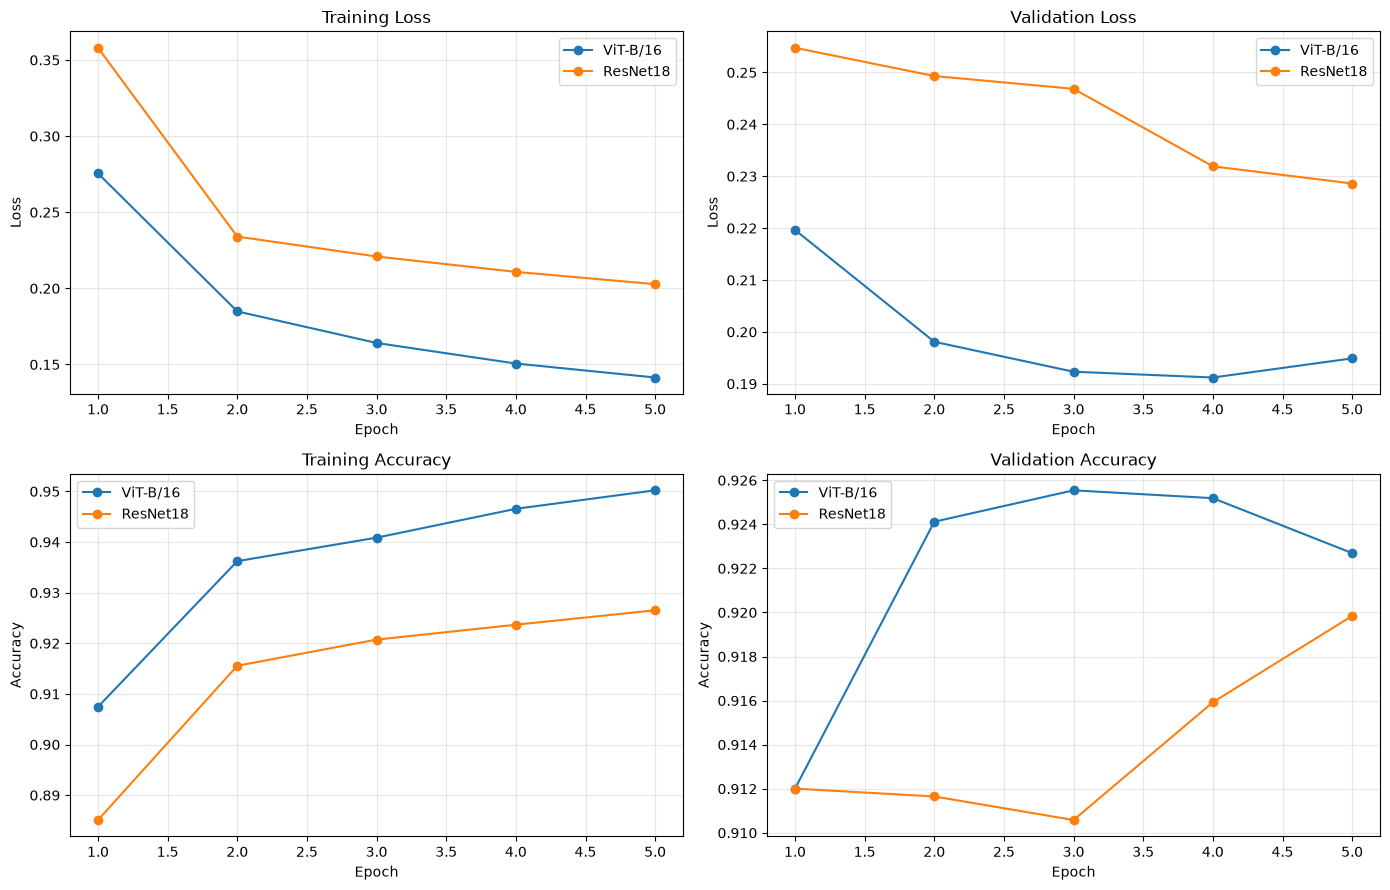

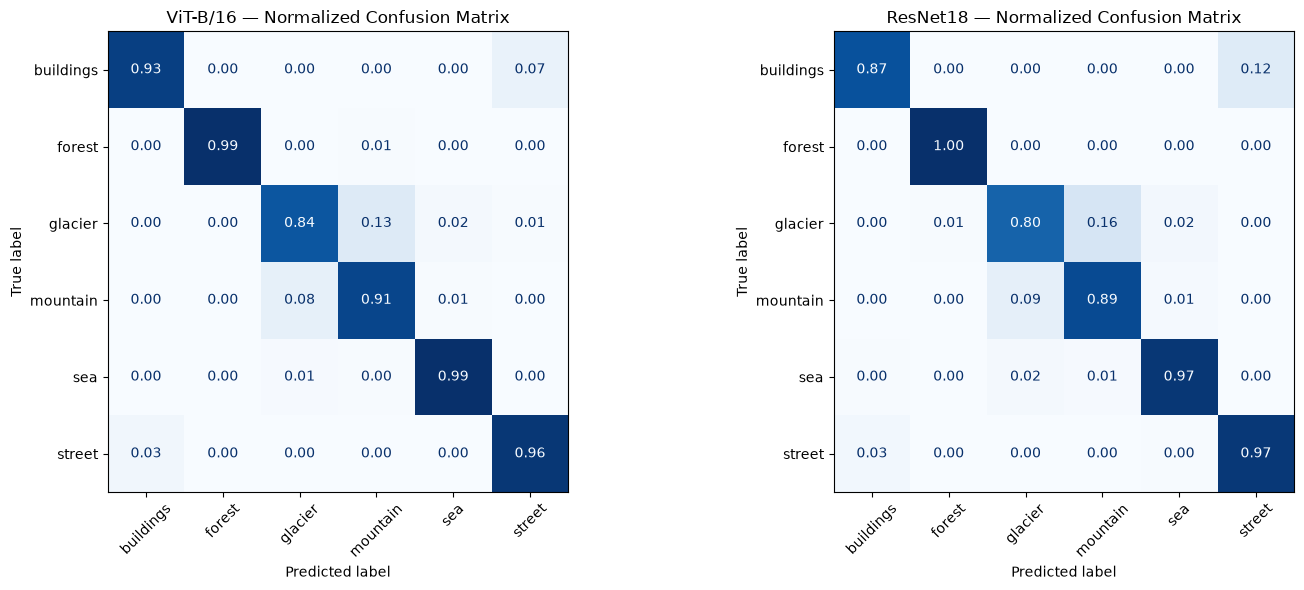

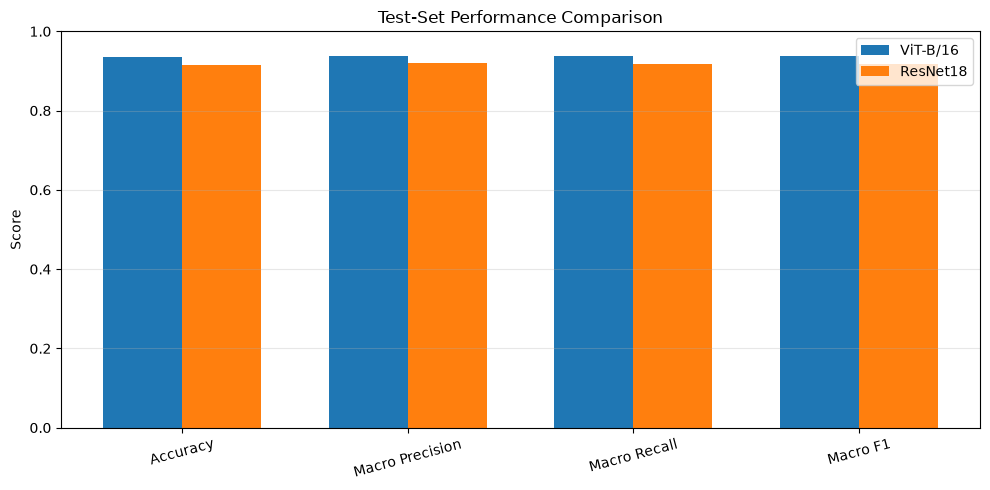


Saved visualization files:
outputs/results/normalized_confusion_matrices.png: 297.5 KB
outputs/results/test_performance_comparison.png: 95.8 KB
outputs/results/training_validation_curves.png: 434.2 KB


In [7]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

RESULTS_DIR = Path("outputs/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Training and validation curves
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for name, history in {
    "ViT-B/16": vit_history,
    "ResNet18": resnet_history,
}.items():
    epochs = [record["epoch"] for record in history]

    axes[0, 0].plot(epochs, [r["train_loss"] for r in history],
                    marker="o", label=name)
    axes[0, 1].plot(epochs, [r["val_loss"] for r in history],
                    marker="o", label=name)
    axes[1, 0].plot(epochs, [r["train_accuracy"] for r in history],
                    marker="o", label=name)
    axes[1, 1].plot(epochs, [r["val_accuracy"] for r in history],
                    marker="o", label=name)

titles = [
    "Training Loss", "Validation Loss",
    "Training Accuracy", "Validation Accuracy",
]

for ax, title in zip(axes.flat, titles):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0, 0].set_ylabel("Loss")
axes[0, 1].set_ylabel("Loss")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 1].set_ylabel("Accuracy")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_validation_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Normalized confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, results, title in [
    (axes[0], vit_test_results, "ViT-B/16"),
    (axes[1], resnet_test_results, "ResNet18"),
]:
    cm = np.asarray(results["confusion_matrix"])
    normalized_cm = cm / cm.sum(axis=1, keepdims=True)

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=normalized_cm,
        display_labels=class_names,
    )
    display_obj.plot(ax=ax, cmap="Blues", values_format=".2f",
                     colorbar=False)
    ax.set_title(f"{title} — Normalized Confusion Matrix")
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "normalized_confusion_matrices.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Aggregate metric comparison
metric_names = [
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]

vit_values = [
    vit_test_results["test_accuracy"],
    vit_test_results["test_macro_precision"],
    vit_test_results["test_macro_recall"],
    vit_test_results["test_macro_f1"],
]

resnet_values = [
    resnet_test_results["test_accuracy"],
    resnet_test_results["test_macro_precision"],
    resnet_test_results["test_macro_recall"],
    resnet_test_results["test_macro_f1"],
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width / 2, vit_values, width, label="ViT-B/16")
ax.bar(x + width / 2, resnet_values, width, label="ResNet18")
ax.set_ylabel("Score")
ax.set_title("Test-Set Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metric_names, rotation=15)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_performance_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved visualization files:")
for path in sorted(RESULTS_DIR.glob("*.png")):
    print(f"{path}: {path.stat().st_size / 1024:.1f} KB")

### Performance Visualization and Comparative Analysis

The training and validation curves indicate that both pre-trained models learned useful representations for image classification. ViT-B/16 achieved lower training and validation losses than ResNet18 and attained a higher validation accuracy. Its validation accuracy peaked at approximately 92.55% in epoch 3, while ResNet18 achieved approximately 91.98% in epoch 5.

On the held-out test set, ViT-B/16 achieved an accuracy of 93.57% and a macro F1-score of 93.75%, outperforming ResNet18, which achieved an accuracy of 91.50% and a macro F1-score of 91.67%. The normalized confusion matrices show that both models classified forest and sea images effectively, whereas glacier and mountain images were more frequently confused due to their visual similarities.

Overall, ViT-B/16 performed better than ResNet18 in this experiment across all four reported test metrics. The results support the effectiveness of transfer learning with a pre-trained Vision Transformer for natural scene classification. However, the experiment used frozen pre-trained backbones with trained classification heads, so further improvements could be explored through selective fine-tuning and additional regularization.